# IS 4487 Assignment 7: Data Transformation with Airbnb Listings

In this assignment, you will:
- Load the Airbnb dataset you cleaned in Assignment 6
- Apply data transformation techniques like scaling, binning, encoding, and feature creation
- Make the dataset easier to use for tasks like pricing analysis, guest segmentation, or listing recommendations
- Practice writing up your analysis clearly so a business audience — like a host, marketing manager, or city partner — could understand it

## Why This Matters

Airbnb analysts, hosts, and city partners rely on clean and well-structured data to make smart decisions. Whether they’re adjusting prices, identifying high-performing listings, or designing better guest experiences, they need data that’s transformed, organized, and ready for use.

This assignment helps you practice that kind of real-world thinking: taking messy real data and getting it ready for action.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_07_data_transformation.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Dataset Description

The dataset you'll be using is a **detailed Airbnb listing file**, available from [Inside Airbnb](https://insideairbnb.com/get-the-data/).

Each row represents one property listing. The columns include:

- **Host attributes** (e.g., host ID, host name, host response time)
- **Listing details** (e.g., price, room type, minimum nights, availability)
- **Location data** (e.g., neighborhood, latitude/longitude)
- **Property characteristics** (e.g., number of bedrooms, amenities, accommodates)
- **Calendar/booking variables** (e.g., last review date, number of reviews)

The schema is consistent across cities, so you can expect similar columns regardless of the location you choose.

Choose a City & Upload Your Dataset
📥 Follow these steps:

Go to: https://insideairbnb.com/get-the-data/
Choose a city you’re interested in.
Download the file named: listings.csv.gz under that city.
In your notebook:
Open the left sidebar
Click the folder icon 📁
Click the upload icon ⬆️ and choose your listings.csv.gz file
Use the file path /content/listings.csv.gz when loading your data.
Import standard libraries (pandas, numpy, seaborn, matplotlib)

## 1. Setup and Load Your Data

You'll be working with the `cleaned_airbnb_data_6.csv` file you exported from Assignment 6. (Note: If you had significant errors with assignment 6, you can use the file named "airbnb_listings.csv" in the DataSets folder on GitHub as a backup starting point.)

### Do the following:
In Google Colab:
- Click the folder icon on the left sidebar
- Use the upload button to add your CSV file to the session
- Then use the code block below to read it into your notebook

Before getting started, make sure you import the libraries you'll need for this assignment:
- `pandas`, `numpy` for data manipulation
- `matplotlib.pyplot`, `seaborn` for visualizations


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('cleaned_airbnb_data_6.csv')

df.head()

print("Dataset shape:", df.shape)
df.info()

Dataset shape: (13225, 84)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13225 entries, 0 to 13224
Data columns (total 84 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            13225 non-null  int64  
 1   source                                        13225 non-null  object 
 2   name                                          13225 non-null  object 
 3   description                                   13088 non-null  object 
 4   neighborhood_overview                         0 non-null      float64
 5   host_id                                       13225 non-null  int64  
 6   host_profile_id                               13193 non-null  float64
 7   host_profile_url                              13201 non-null  object 
 8   host_name                                     13225 non-null  object 
 9   host_since                        

## 2. Check for Skew in a Numeric Column

### Business framing:  

Airbnb listings can have a wide range of values for things like price, availability, or reviews. These kinds of distributions can be hard to visualize, summarize, or model.

### Do the following:
Choose one **numeric column** that appears skewed and do the following:
- Plot a histogram
- Apply a transformation (e.g., log or other method)
- Plot again to compare

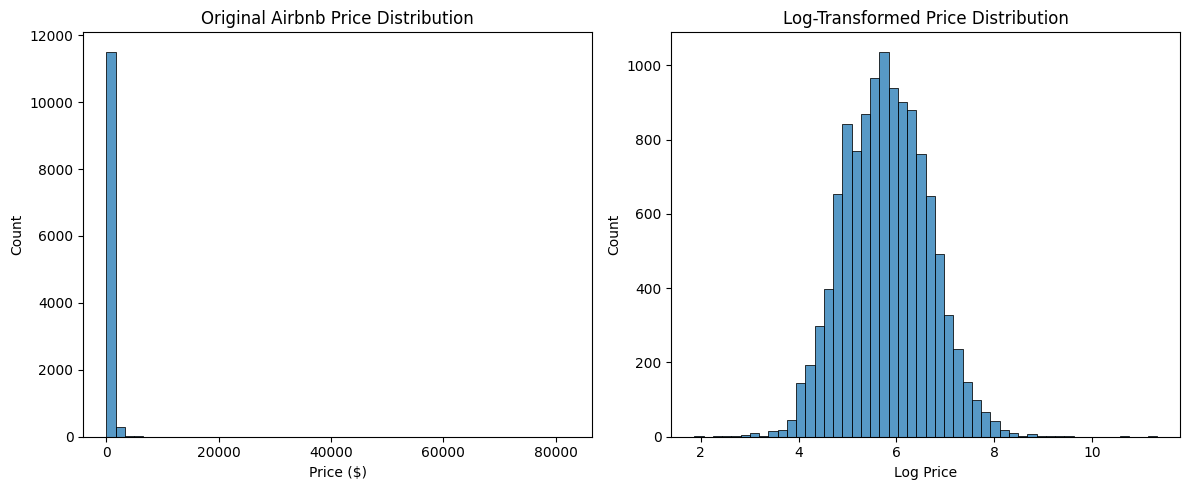

In [9]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['price'].dropna(), bins=50)
plt.title('Original Airbnb Price Distribution')
plt.xlabel('Price ($)')
plt.ylabel('Count')

df['log_price'] = np.log1p(df['price'])

plt.subplot(1, 2, 2)
sns.histplot(df['log_price'].dropna(), bins=50)
plt.title('Log-Transformed Price Distribution')
plt.xlabel('Log Price')
plt.ylabel('Count')

plt.tight_layout()
plt.show()

### Reflection:
1. What column did you examine?
2. What transformation did you try, and why?
3. How did the transformed version help make the data more usable for analysis or stakeholder review?

### ✍️ Your Response: 🔧
1. I examined the price column because Airbnb listings have a wide range of prices, and some listings are significantly more expensive than others. This makes the distribution skewed to the right.

2. I applied a log transformation using np.log1p() to reduce the impact of extremely high prices. This helps compress larger values and makes the distribution less skewed without removing any listings.

3. The log transformation makes it easier to visualize and compare typical Airbnb listing prices because expensive outliers no longer dominate the distribution. This can help hosts and analysts better understand pricing patterns and make more informed pricing decisions.

## 3. Scale Two Numeric Columns

### Business framing:

If an analyst wanted to compare listing price to number of nights required, or create a model that weighs both, those values need to be on a similar scale.

### Do the following:
- Pick two numeric columns with different value ranges (e.g. one column may have a min of 0 and a max of 255; another column may have a min of 100 and a max of 400)
- Use Min-Max scaling on one column (the range should be “shrinked” down to just 0-1)
- Use Z-score Normalization (aka standardization) on the other column.
- Add 2 new columns to the dataset. These 2 new columns should be the ones you just created.

In [12]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# Min-Max scale price
minmax_scaler = MinMaxScaler()
df['price_scaled'] = minmax_scaler.fit_transform(df[['price']])

# Z-score scale minimum nights
standard_scaler = StandardScaler()
df['minimum_nights_scaled'] = standard_scaler.fit_transform(df[['minimum_nights']])

# Display the results
df[['price', 'price_scaled', 'minimum_nights', 'minimum_nights_scaled']].head()

,price,price_scaled,minimum_nights,minimum_nights_scaled
0,NaN,NaN,31.0,0.906112
1,226.06,0.002679,31.0,0.906112
2,398.58,0.004774,2.0,-0.450471
3,NaN,NaN,3.0,-0.403693
4,162.57,0.001908,1.0,-0.497250



### Reflection:
1. What two columns did you scale, and which methods did you use?
2. When might these scaled values be more useful than the originals?
3. Who at Airbnb might benefit from this transformation and why?

### ✍️ Your Response: 🔧
1. I scaled the price column using Min-Max scaling and the minimum_nights column using Z-score standardization. Min-Max scaling converted prices to a range between 0 and 1, while Z-score standardization adjusted minimum nights based on its mean and standard deviation.

2. These scaled values would be useful when comparing variables with different numerical ranges or building machine learning models. Scaling prevents variables with larger values, such as price, from having too much influence simply because of their numerical size.

3. Airbnb data analysts and pricing teams could benefit from these transformations because they make it easier to compare listing characteristics and develop pricing or recommendation models. This could help identify pricing patterns and improve listing recommendations for guests.

## 4. Group a Numeric Column into Categories

### Business framing:  

Let’s say an Airbnb marketing team wants to segment listings by review activity. They don’t want exact numbers — they just want to know if a listing has “low,” “medium,” or “high” review volume.

### Do the following:

- Choose a numeric column that could be grouped (e.g., reviews, availability).
- You’ll want to group the values of this column into 3 or 4 bins
- Create a new column. The values of this column will be the labels: “Low”, “Medium”, and “High.” These labels should correspond to your bins.

In [15]:
df['review_category'] = pd.cut(
    df['number_of_reviews'],
    bins=[-1, 10, 50, float('inf')],
    labels=['Low', 'Medium', 'High'])

df[['number_of_reviews', 'review_category']].head()

,number_of_reviews,review_category
0,0,Low
1,0,Low
2,207,High
3,21,Medium
4,58,High


### Reflection:
1. What column did you group, and how many categories did you use?
2. Why might someone prefer this grouped view over raw numbers?
3. Who would this help at Airbnb, and how?

### ✍️ Your Response: 🔧
1. I grouped the number of reviews column into three categories: Low, Medium, and High.

2. I think grouping reviews into categories makes it easier to compare listings without looking at individual review counts. It simplifies the data and helps identify patterns in review activity, making the information easier to understand and analyze.

3. Airbnb's marketing team could benefit from these categories because they can segment listings based on review activity. This could help them identify listings with fewer reviews that may need more promotion or highlight listings with higher review activity in marketing campaigns.

## 5. Create Two New Business-Relevant Variables

### Business framing:  

Stakeholders often want to know things like: What’s the cost per night? Are listings geared toward long-term stays? These kinds of features aren’t always in the dataset — analysts create them.

### Do the following:

- Think of two new columns you can create using the data you already have.
  - One might be a ratio or interaction between columns (e.g., price ÷ nights).
  - The other might be a flag based on a condition (e.g., stays longer than 30 days).
- Add the new columns to your DataFrame.

In [17]:
df['price_per_guest'] = df['price'] / df['accommodates'].replace(0, np.nan)

df['long_term_stay'] = (df['minimum_nights'] >= 30).astype(int)

df[['price', 'accommodates', 'price_per_guest',
    'minimum_nights', 'long_term_stay']].head()

,price,accommodates,price_per_guest,minimum_nights,long_term_stay
0,NaN,1,NaN,31.0,1
1,226.06,4,56.5150,31.0,1
2,398.58,8,49.8225,2.0,0
3,NaN,2,NaN,3.0,0
4,162.57,6,27.0950,1.0,0


### Reflection:
1. What two new columns did you create and why?
2. Who would use them (e.g., host, manager, or platform)?
3. How could they help someone make a better decision?

### ✍️ Your Response: 🔧
1. I created two new columns. price per guest and long term stay. The price_per_guest column calculates the nightly price divided by the number of guests a listing can accommodate, while long term stay identifies listings that require a minimum stay of 30 nights or more. These variables make it easier to compare listing affordability and minimum stay requirements.

2. Airbnb hosts and platform analysts could benefit from these variables. Hosts could use price per guest to compare their pricing with similar properties, while analysts could use long term stay to identify and categorize listings with extended minimum stay requirements.

3. These variables could help hosts make better pricing decisions by comparing the cost per guest across different listings. They could also help Airbnb analysts identify properties with longer minimum stay requirements and better understand different types of listings. This could improve pricing strategies and help guests find properties that match their needs.



## 6. Encode a Categorical Column

### Business framing:  

Let’s say you’re helping the Airbnb data science team build a model to predict booking rates. Categorical columns like `room_type`, `neighbourhood`, or `cancellation_policy` can’t be used in models unless they’re converted to numbers.

### Do the following:
- Choose one categorical column from your dataset (e.g., room type or neighborhood group)
- Decide on an encoding method:
  - Use one-hot encoding for nominal (unordered) categories
  - Use ordinal encoding (a ranking) only if the categories have a clear order
- Apply the encoding using `pandas` or another tool
- Add the new encoded column(s) to your DataFrame

In [18]:
room_encoded = pd.get_dummies(df['room_type'], prefix='room_type', dtype=int)

df = pd.concat([df, room_encoded], axis=1)

df[['room_type'] + room_encoded.columns.tolist()].head()

,room_type,room_type_Entire home/apt,room_type_Hotel room,room_type_Private room,room_type_Shared room
0,Private room,0,0,1,0
1,Entire home/apt,1,0,0,0
2,Entire home/apt,1,0,0,0
3,Private room,0,0,1,0
4,Entire home/apt,1,0,0,0


### Reflection:
1. What column did you encode and why?
2. What encoding method did you use?
3. How could this transformation help a pricing model, dashboard, or business report?

### ✍️ Your Response: 🔧
1. I encoded the room type column because it contains categorical values such as entire homes, private rooms, and shared rooms. These categories need to be converted into numerical values so machine learning models can use them for analysis and predictions.
2. I used one-hot encoding with pd.get_dummies() to create separate binary columns for each room type. Each column uses 1 to indicate that a listing belongs to that category and 0 if it does not. This method works well because room types do not have a natural numerical ranking.
3. One-hot encoding could help Airbnb analysts identify how different room types influence listing prices and booking patterns. By converting room types into numerical features, pricing models can analyze differences between entire homes, private rooms, and shared rooms. This could help hosts make better pricing decisions and improve Airbnb's listing recommendations.

## 7. Export Cleaned Data

Before wrapping up, export your cleaned Airbnb dataset to a CSV file. You'll need this file for **Assignment 11**, where you'll use the data in a regression model.

### Do the following:
Make sure your data has:
- Cleaned and consistent column values
- Proper data types for each column
- Any unnecessary columns removed

This file should be the version of your dataset that you’d feel confident sharing with a teammate or using for deeper analysis.



```
# Explanation:
# - "cleaned_airbnb_data_7.csv" is the name of the file that will be saved
# - index=False prevents pandas from writing row numbers into the CSV
# - The file will be saved to your working directory (in Colab, you'll need to download it manually. Once you see the data in your files tab, just click on the three dots, then click “download”)
# - YOU MAY NEED TO PRESS “RUN” MULTIPLE TIMES IN ORDER FOR IT TO SHOW UP
# - FOR SOME DEVICES, IT MAY TAKE A FEW MINUTES BEFORE YOUR FILE SHOWS UP

```

In [20]:
df.to_csv('cleaned_airbnb_data_7.csv', index=False)

print("Dataset exported successfully!")
print("Final dataset shape:", df.shape)

Dataset exported successfully!
Final dataset shape: (13225, 94)


## 8. Reflection

You’ve applied the same kinds of transformation techniques used in real Airbnb analytics projects — from pricing engines to host tools to tourism dashboards.

Now step back and reflect.

### Reflection:
1. What transformation step felt most important or interesting?
2. Which of your changes would be most useful to a host, analyst, or city planner?
3. If you were going to build a tool or dashboard, what would you do next with this data?
4. How does this relate to your customized learning outcome you created in canvas?



### ✍️ Your Response: 🔧

1. I think feature creation was the most interesting transformation because it allowed me to create new variables using existing data. Creating price per guest and long term stay showed me how raw data can be transformed into information that is more useful for business analysis and decision making.

2. I think the price per guest variable would be especially useful to Airbnb hosts and analysts. It allows them to compare the affordability of listings based on how many guests they can accommodate. This could help hosts evaluate their pricing strategies and remain competitive with similar properties.

3. If I were building a dashboard, I would create visualizations comparing listing prices, room types, neighborhoods, and review activity. I would also include filters so users could compare properties based on their preferences. This could help hosts identify pricing trends and help guests find listings that fit their budgets.
4. This assignment relates to my customized learning outcomes of Data Visualization & Communication and Ethical Considerations in Analytics. Transforming the Airbnb data helped me understand how to organize and present information in a way that is easier for stakeholders to interpret. It also showed me the importance of using accurate data and choosing appropriate transformations to avoid misleading results. These skills relate to my career goal in financial consulting, where I will need to communicate financial information clearly and make responsible decisions using client data.



## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_07_data_transformation.ipynb"